# Phase-0 Pilot — Energy of Think vs. No-Think (Qwen3-8B)

**Goal (de-risk the real pipeline before spending GPU credits).** Run a small
paired study on Qwen3-8B over OptimalThinkingBench, toggling only
`enable_thinking`, and measure **real GPU energy (Wh)** per query with **Zeus**.

This pilot answers three plumbing questions and produces three numbers:

**Does it work?**
1. Does **Zeus read NVML energy** on this Colab GPU?
2. Does **vLLM toggle `enable_thinking`** and emit parseable `<think>...</think>`?
3. Can we get **clean per-query attribution** at low concurrency?

**What do we learn?**
- The **Wh-vs-output-tokens scatter** (the RQ1 spine: does token count predict energy?).
- Mean **Wh/query** for think and no-think → used to **size the Phase-1 GPU budget**.

> Runtime: set **Runtime → Change runtime type → A100 GPU** before running.
> Everything is **resumable** — results append to a JSONL, so a crash or a
> Colab restart (vLLM install often forces one) never loses completed work.

## 0. Colab + GitHub setup (run first when on Colab)

Open this straight from the private repo:
`https://colab.research.google.com/github/cemalgndzz/llm-routing-tesina/blob/main/notebooks/00_pilot_energy_measurement.ipynb`
(Colab will ask you to authorize GitHub and to *include private repos*.)

**Save notebook edits back to GitHub:** use **File → Save a copy in GitHub** in
the Colab menu — it commits this `.ipynb` to the repo (pick branch `main`). No
code needed; it uses Colab's GitHub authorization.

**Work with the rest of the repo** (`scripts/`, `src/`, configs) and push other
files: run the cell below. It clones the repo into the runtime using a GitHub
token. Add the token once in Colab → **key icon (left sidebar) → + Add new
secret**, name `GITHUB_TOKEN`, value = a fine-grained PAT with *Contents: Read
and write* on this repo, and toggle **Notebook access** on.

In [1]:
import os, subprocess

REPO   = "cemalgndzz/llm-routing-tesina"
BRANCH = "main"

TOKEN = None
try:
    from google.colab import userdata            # present only on Colab
    TOKEN = userdata.get("GITHUB_TOKEN")
except Exception as e:
    print("Not on Colab or no GITHUB_TOKEN secret:", repr(e)[:120])

if TOKEN:
    repo_dir = "/content/" + REPO.split("/")[1]
    auth_url = f"https://{TOKEN}@github.com/{REPO}.git"      # token stays in this runtime only
    if not os.path.isdir(os.path.join(repo_dir, ".git")):
        subprocess.run(["git", "clone", "--branch", BRANCH, auth_url, repo_dir], check=True)
    else:
        subprocess.run(["git", "-C", repo_dir, "pull", "--ff-only"], check=True)
    os.chdir(repo_dir)
    subprocess.run(["git", "remote", "set-url", "origin", auth_url], check=True)
    subprocess.run(["git", "config", "user.name", "cemalgndzz"], check=True)
    subprocess.run(["git", "config", "user.email", "cgogit@gmail.com"], check=True)
    print("Repo ready. Working dir:", os.getcwd())
else:
    print("No token -> running standalone (notebook still works; it pulls data/model from HF).")

Repo ready. Working dir: /content/llm-routing-tesina


In [2]:
# Push files you changed in the CLONED repo back to GitHub.
# (For the notebook itself, prefer File > Save a copy in GitHub.)
# Note: data/, results/ and *.jsonl are gitignored -> pilot outputs are NOT pushed.
import subprocess, datetime

BRANCH = "main"
COMMIT_MESSAGE = "Update from Colab " + datetime.datetime.now().strftime("%Y-%m-%d %H:%M")

subprocess.run(["git", "add", "-A"], check=True)
changed = subprocess.run(["git", "status", "--porcelain"], capture_output=True, text=True).stdout.strip()
if changed:
    subprocess.run(["git", "commit", "-m", COMMIT_MESSAGE], check=True)
    subprocess.run(["git", "push", "origin", BRANCH], check=True)
    print("Pushed to GitHub.")
else:
    print("Nothing to commit.")

Nothing to commit.


## 1. Environment check

In [3]:
import subprocess, torch
smi = subprocess.run(
    ["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
    capture_output=True, text=True)
print("nvidia-smi:", smi.stdout.strip() or smi.stderr.strip())
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

/usr/local/lib/python3.12/dist-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


nvidia-smi: NVIDIA A100-SXM4-80GB, 81920 MiB, 580.82.07
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB
VRAM (GB): 85.1


## 2. Install dependencies

`zeus-ml` (energy), `datasets` (OptimalThinkingBench), `pynvml` (fallback power),
plus **vLLM** (preferred serving engine). If the vLLM install errors or Colab
asks to **restart the runtime**, restart and re-run from the *Config* cell — the
loop is resumable and the serving cell falls back to HF Transformers automatically.

In [7]:
!pip uninstall -y amdsmi pyamdsmi

Found existing installation: amdsmi 7.0.2
Uninstalling amdsmi-7.0.2:
  Successfully uninstalled amdsmi-7.0.2


In [7]:
!pip install -q "vllm==0.11.0" "transformers==4.57.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.4/41.4 kB 4.3 MB/s eta 0:00:00
Reason for being yanked: Error in the setup causing installation issues
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 438.2/438.2 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 147.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 154.3 MB/s eta 0:00:00


In [4]:
# Core deps. transformers pinned <5 (v5.0 breaks vLLM's Qwen tokenizer).
%pip install -q -U zeus-ml datasets pynvml accelerate "transformers>=4.51,<5"

%pip install -q "vllm>=0.10,<0.11"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 227.1/227.1 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.1/555.1 kB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 52.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.0/215.0 kB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 436.4/436.4 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.0/180.0 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 123.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 117.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88

## 3. Config

Start with `SMOKE_TEST = True` (a 6-generation sanity run, ~minutes). Once the
whole notebook runs clean end-to-end, set `SMOKE_TEST = False` and re-run the
loop for the real ~50-query pilot.

In [14]:
import os, random, numpy as np

SMOKE_TEST = False                 # True = tiny sanity run; False = full pilot
MODEL = "Qwen/Qwen3-8B"
N_PER_SUBSET = 3 if SMOKE_TEST else 25     # queries from each of over/under-thinking
REPS = 1 if SMOKE_TEST else 3              # repeats per (query, mode) for variance/CIs
THINK_MAX_TOKENS = 1024 if SMOKE_TEST else 8192
NOTHINK_MAX_TOKENS = 512 if SMOKE_TEST else 1024
SEED = 12345

OUTDIR = "results/pilot"
os.makedirs(OUTDIR, exist_ok=True)
RESULTS_JSONL = os.path.join(OUTDIR, "pilot_results.jsonl")

random.seed(SEED); np.random.seed(SEED)

# Qwen3 recommended sampling (thinking vs non-thinking presets)
SAMPLING = {
    "think":    dict(temperature=0.6, top_p=0.95, top_k=20, max_tokens=THINK_MAX_TOKENS),
    "no_think": dict(temperature=0.7, top_p=0.80, top_k=20, max_tokens=NOTHINK_MAX_TOKENS),
}
print("SMOKE_TEST =", SMOKE_TEST, "| N_PER_SUBSET =", N_PER_SUBSET, "| REPS =", REPS)

SMOKE_TEST = False | N_PER_SUBSET = 25 | REPS = 3


## 4. Load OptimalThinkingBench and sample queries

`subset == "overthinkingbench"` → think is wasted → **ground-truth label `no_think`**.
`subset == "underthinkingbench"` → think is needed → **ground-truth label `think`**.
(The HF release excludes the math subsets, which is fine for the pilot.) For the
overthinking side we prefer auto-scorable answer types so correctness is
checkable without an LLM judge in the pilot.

In [15]:
import json
from collections import Counter
from datasets import load_dataset

ds = load_dataset("facebook/optimal_thinking_bench")["train"]

def parse_meta(m):
    if isinstance(m, dict):
        return m
    try:
        return json.loads(m)
    except Exception:
        return {}

rows = []
for r in ds:
    meta = parse_meta(r.get("metadata"))
    rows.append({
        "question": r["question"],
        "answer": r.get("answer", ""),
        "subset": r["subset"],
        "answer_type": str(meta.get("answer_type", "unknown")),
        "domain": str(meta.get("domain", "unknown")),
    })

over  = [r for r in rows if r["subset"] == "overthinkingbench"]
under = [r for r in rows if r["subset"] == "underthinkingbench"]

scorable = {"numeric", "multiple-choice", "mcq", "short", "short-answer", "one-word", "short-phrase"}
over_pref = [r for r in over if r["answer_type"].lower() in scorable] or over
random.shuffle(over_pref); random.shuffle(under)

sample = []
for i, r in enumerate(over_pref[:N_PER_SUBSET]):
    r = dict(r); r["qid"] = f"over_{i:03d}"; r["route_label"] = "no_think"; sample.append(r)
for i, r in enumerate(under[:N_PER_SUBSET]):
    r = dict(r); r["qid"] = f"under_{i:03d}"; r["route_label"] = "think"; sample.append(r)

print(f"OTB rows={len(ds)} | over={len(over)} under={len(under)} | sampled={len(sample)}")
print("answer types in sample:", dict(Counter(r["answer_type"] for r in sample)))
print("\nExample:", sample[0]["qid"], "|", sample[0]["question"][:120])

Repo card metadata block was not found. Setting CardData to empty.


OTB rows=1877 | over=1327 under=550 | sampled=50
answer types in sample: {'numeric': 15, 'mcq': 10, 'unknown': 25}

Example: over_000 | How many neutrons are in the nucleus of a Carbon-12 atom?


## 5. Serving layer — vLLM first, HF Transformers fallback

A unified `generate(question, mode)` builds the Qwen3 chat prompt with
`enable_thinking` on/off, generates, and reports prompt / completion / **thinking**
token counts (parsed at the `</think>` delimiter).

In [6]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(MODEL)

BACKEND, llm, hf_model = None, None, None
try:
    from vllm import LLM, SamplingParams
    llm = LLM(model=MODEL, dtype="bfloat16", gpu_memory_utilization=0.90,
              max_model_len=16384, enforce_eager=False)
    BACKEND = "vllm"
except Exception as e:
    print("vLLM unavailable -> HF Transformers fallback. Reason:", repr(e)[:300])
    from transformers import AutoModelForCausalLM
    hf_model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.bfloat16, device_map="cuda")
    BACKEND = "hf"
print("BACKEND =", BACKEND)

def build_prompt(question, think):
    messages = [{"role": "user", "content": question}]
    return tok.apply_chat_template(messages, tokenize=False,
                                   add_generation_prompt=True, enable_thinking=think)

def split_think(text):
    # Qwen3 emits <think>...</think> then the final answer.
    if "</think>" in text:
        think_part, _, answer_part = text.partition("</think>")
        return think_part.replace("<think>", "").strip(), answer_part.strip()
    return "", text.strip()

def n_tokens(s):
    return len(tok(s, add_special_tokens=False)["input_ids"]) if s else 0

def generate(question, mode):
    think = (mode == "think")
    prompt = build_prompt(question, think)
    sp = SAMPLING[mode]
    if BACKEND == "vllm":
        from vllm import SamplingParams
        params = SamplingParams(temperature=sp["temperature"], top_p=sp["top_p"],
                                top_k=sp["top_k"], max_tokens=sp["max_tokens"])
        out = llm.generate([prompt], params, use_tqdm=False)[0]
        text = out.outputs[0].text
        completion_tokens = len(out.outputs[0].token_ids)
        prompt_tokens = len(out.prompt_token_ids)
    else:
        inputs = tok(prompt, return_tensors="pt").to("cuda")
        prompt_tokens = int(inputs["input_ids"].shape[1])
        gen = hf_model.generate(**inputs, do_sample=True, temperature=sp["temperature"],
                                top_p=sp["top_p"], top_k=sp["top_k"], max_new_tokens=sp["max_tokens"])
        gen_ids = gen[0][prompt_tokens:]
        text = tok.decode(gen_ids, skip_special_tokens=True)
        completion_tokens = int(gen_ids.shape[0])
    think_text, answer_text = split_think(text)
    return {"text": text, "think_text": think_text, "answer_text": answer_text,
            "prompt_tokens": prompt_tokens, "completion_tokens": completion_tokens,
            "think_tokens": n_tokens(think_text)}

INFO 07-03 13:07:51 [__init__.py:216] Automatically detected platform cuda.
INFO 07-03 13:07:56 [utils.py:233] non-default args: {'dtype': 'bfloat16', 'max_model_len': 16384, 'disable_log_stats': True, 'model': 'Qwen/Qwen3-8B'}
INFO 07-03 13:07:58 [model.py:547] Resolved architecture: Qwen3ForCausalLM


`torch_dtype` is deprecated! Use `dtype` instead!


INFO 07-03 13:07:58 [model.py:1510] Using max model len 16384
INFO 07-03 13:08:00 [scheduler.py:205] Chunked prefill is enabled with max_num_batched_tokens=8192.
WARNING 07-03 13:08:02 [__init__.py:3036] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized
INFO 07-03 13:09:34 [llm.py:306] Supported_tasks: ['generate']
BACKEND = vllm


## 6. Energy measurement (Zeus) + idle baseline + warm-up

`measure(fn)` wraps a single generation in a Zeus energy window for clean
per-query attribution at low concurrency (one query at a time). If Zeus can't
init, it falls back to integrating NVML power over the call. We also record an
idle-power baseline (context) and do one **un-recorded warm-up** per mode to
avoid lazy-init skew.

> **Attribution caveat:** this is the controlled low-concurrency setting. Energy
> attribution under real *batched* serving is a separate (harder) question we
> handle in a later phase — see CLAUDE.md §4.5.

In [16]:
import time, threading

zeus_ok = False
try:
    from zeus.monitor import ZeusMonitor
    zmon = ZeusMonitor(gpu_indices=[0])
    zeus_ok = True
    print("Zeus monitor ready.")
except Exception as e:
    print("Zeus unavailable:", repr(e)[:200], "-> NVML power-sampling fallback.")

import pynvml
pynvml.nvmlInit()
_NVH = pynvml.nvmlDeviceGetHandleByIndex(0)

def measure(fn):
    """Run fn(); return (result, energy_wh, seconds)."""
    if zeus_ok:
        zmon.begin_window("q")
        r = fn()
        m = zmon.end_window("q")
        energy_j = getattr(m, "total_energy", None)
        if energy_j is None:
            energy_j = sum(m.gpu_energy.values())
        return r, energy_j / 3600.0, m.time
    samples, stop = [], threading.Event()
    def sampler():
        while not stop.is_set():
            samples.append(pynvml.nvmlDeviceGetPowerUsage(_NVH) / 1000.0)  # W
            time.sleep(0.05)
    t0 = time.time(); th = threading.Thread(target=sampler); th.start()
    r = fn()
    stop.set(); th.join(); dt = time.time() - t0
    avg_w = sum(samples) / len(samples) if samples else float("nan")
    return r, avg_w * dt / 3600.0, dt

def idle_power_w(seconds=3):
    s, t = [], time.time()
    while time.time() - t < seconds:
        s.append(pynvml.nvmlDeviceGetPowerUsage(_NVH) / 1000.0); time.sleep(0.1)
    return sum(s) / len(s) if s else float("nan")

IDLE_W = idle_power_w(3)
print("Idle GPU power (W):", round(IDLE_W, 1))

_ = generate(sample[0]["question"], "no_think")   # warm-up (not recorded)
_ = generate(sample[0]["question"], "think")
print("Warm-up done.")

[2026-07-03 13:15:29,178] [zeus.monitor.energy](energy.py:209) Monitoring GPU indices [0].
[2026-07-03 13:15:29,178] [zeus.monitor.energy](energy.py:210) Monitoring CPU indices []
Zeus monitor ready.
Idle GPU power (W): 63.8
Warm-up done.


## 7. Lightweight correctness scoring

Pilot-grade automatic scoring: pull the final answer (last `\boxed{}`, else
`Answer:`, else last line), then numeric- or normalized-string-compare to gold.
Open-ended-long answers return `None` (they need an LLM judge — that's Phase 1).

In [17]:
import re

def extract_answer(answer_text):
    m = re.findall(r"\\boxed\{([^}]*)\}", answer_text)
    if m:
        return m[-1].strip()
    m = re.search(r"(?i)answer\s*[:=]\s*(.+)", answer_text)
    if m:
        return m.group(1).strip().splitlines()[0].strip()
    lines = [l.strip() for l in answer_text.splitlines() if l.strip()]
    return lines[-1] if lines else ""

def _norm(s):
    return re.sub(r"[^a-z0-9.]+", "", str(s).lower())

def _try_float(s):
    m = re.search(r"-?\d+\.?\d*", str(s).replace(",", ""))
    return float(m.group()) if m else None

def is_correct(answer_text, gold, answer_type):
    if answer_type and "long" in answer_type.lower():
        return None  # needs LLM judge (Phase 1)
    pred = extract_answer(answer_text)
    a, b = _try_float(pred), _try_float(gold)
    if a is not None and b is not None:
        return bool(abs(a - b) <= 1e-4 * max(1.0, abs(b)))
    np_, ng = _norm(pred), _norm(gold)
    if not ng:
        return None
    return bool(np_ == ng or ng in np_ or np_ in ng)

## 8. Main measurement loop (resumable)

Writes one JSONL row per `(query, mode, rep)`. Re-running skips rows already on
disk, so you can stop/restart freely.

In [18]:
import datetime

done = set()
if os.path.exists(RESULTS_JSONL):
    for line in open(RESULTS_JSONL):
        try:
            d = json.loads(line); done.add((d["qid"], d["mode"], d["rep"]))
        except Exception:
            pass
print("Already on disk:", len(done))

META = {"backend": BACKEND, "model": MODEL, "gpu": torch.cuda.get_device_name(0)}
modes = ["no_think", "think"]
total = len(sample) * len(modes) * REPS
cnt = 0
with open(RESULTS_JSONL, "a") as fout:
    for q in sample:
        for mode in modes:
            for rep in range(REPS):
                cnt += 1
                if (q["qid"], mode, rep) in done:
                    continue
                res, wh, secs = measure(lambda: generate(q["question"], mode))
                corr = is_correct(res["answer_text"], q["answer"], q["answer_type"])
                row = {
                    "qid": q["qid"], "subset": q["subset"], "route_label": q["route_label"],
                    "answer_type": q["answer_type"], "domain": q["domain"],
                    "mode": mode, "rep": rep,
                    "prompt_tokens": res["prompt_tokens"],
                    "completion_tokens": res["completion_tokens"],
                    "think_tokens": res["think_tokens"],
                    "energy_wh": wh, "latency_s": secs, "correct": corr,
                    "idle_w": IDLE_W,
                    "answer_text": res["answer_text"][:2000],
                    "gold": str(q["answer"])[:500],
                    **META,
                    "ts": datetime.datetime.utcnow().isoformat(),
                }
                fout.write(json.dumps(row) + "\n"); fout.flush()
                print(f"[{cnt}/{total}] {q['qid']:>10} {mode:<8} rep{rep}: "
                      f"{wh*1000:7.2f} mWh  {secs:6.1f}s  think={res['think_tokens']:>5}  correct={corr}")
print("Loop complete.")

Already on disk: 12


/tmp/ipykernel_12241/3587098785.py:37: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "ts": datetime.datetime.utcnow().isoformat(),


[2/300]   over_000 no_think rep1:  133.03 mWh     1.7s  think=    0  correct=True
[3/300]   over_000 no_think rep2:  126.80 mWh     1.6s  think=    0  correct=True
[5/300]   over_000 think    rep1:  776.82 mWh     9.7s  think=  597  correct=True
[6/300]   over_000 think    rep2:  946.33 mWh    11.7s  think=  747  correct=True
[8/300]   over_001 no_think rep1:  145.62 mWh     1.8s  think=    0  correct=True
[9/300]   over_001 no_think rep2:   73.04 mWh     0.9s  think=    0  correct=True
[11/300]   over_001 think    rep1: 1474.04 mWh    18.2s  think= 1185  correct=True
[12/300]   over_001 think    rep2:  841.96 mWh    10.4s  think=  631  correct=True
[14/300]   over_002 no_think rep1:   65.36 mWh     0.7s  think=    0  correct=True
[15/300]   over_002 no_think rep2:   49.16 mWh     0.7s  think=    0  correct=True
[17/300]   over_002 think    rep1:  502.21 mWh     6.1s  think=  363  correct=True
[18/300]   over_002 think    rep2:  403.02 mWh     4.9s  think=  242  correct=True
[19/300]  

/usr/local/lib/python3.12/dist-packages/zeus/monitor/energy.py:403: UserWarning: The energy consumption of one or more GPUs was measured as zero. This means that the time duration of the measurement window was shorter than the GPU's energy counter update period. Consider turning on the `approx_instant_energy` option in `ZeusMonitor`, which approximates the energy consumption of a short time window as instant power draw x window duration.
  warnings.warn(


[220/300]  under_011 think    rep0: 8656.90 mWh   104.1s  think=    0  correct=False
[221/300]  under_011 think    rep1: 8662.72 mWh   104.0s  think=    0  correct=True
[222/300]  under_011 think    rep2: 8655.44 mWh   104.1s  think= 8015  correct=False
[223/300]  under_012 no_think rep0: 1037.46 mWh    12.6s  think=    0  correct=False
[224/300]  under_012 no_think rep1: 1049.23 mWh    12.7s  think=    0  correct=False
[225/300]  under_012 no_think rep2: 1037.03 mWh    12.6s  think=    0  correct=True
[226/300]  under_012 think    rep0: 8663.29 mWh   103.9s  think=    0  correct=False
[227/300]  under_012 think    rep1: 8651.79 mWh   103.9s  think=    0  correct=True
[228/300]  under_012 think    rep2: 8655.79 mWh   103.9s  think=    0  correct=True
[229/300]  under_013 no_think rep0:  557.08 mWh     6.8s  think=    0  correct=False
[230/300]  under_013 no_think rep1:  531.35 mWh     6.4s  think=    0  correct=False
[231/300]  under_013 no_think rep2:  614.93 mWh     7.5s  think=    0

## 9. Analysis

In [19]:
import pandas as pd
df = pd.read_json(RESULTS_JSONL, lines=True)
print("rows:", len(df), "| backend:", df["backend"].iloc[0])

agg = df.groupby("mode").agg(
    energy_wh=("energy_wh", "mean"),
    latency_s=("latency_s", "mean"),
    completion_tokens=("completion_tokens", "mean"),
    think_tokens=("think_tokens", "mean"),
).round(4)
print("\nPer-mode means:\n", agg)

sc = df[df["correct"].notna()]
if len(sc):
    print("\nAccuracy (scorable only) by subset/mode:\n",
          sc.groupby(["subset", "mode"])["correct"].mean().round(3))

rows: 300 | backend: vllm

Per-mode means:
           energy_wh  latency_s  completion_tokens  think_tokens
mode                                                           
no_think     0.4105     4.9905           404.9333          0.00
think        4.1117    49.6204          3924.2267       1315.18

Accuracy (scorable only) by subset/mode:
 subset              mode    
overthinkingbench   no_think    0.733
                    think       0.800
underthinkingbench  no_think    0.440
                    think       0.413
Name: correct, dtype: float64


### 9a. RQ1 spine — does output-token count predict energy?

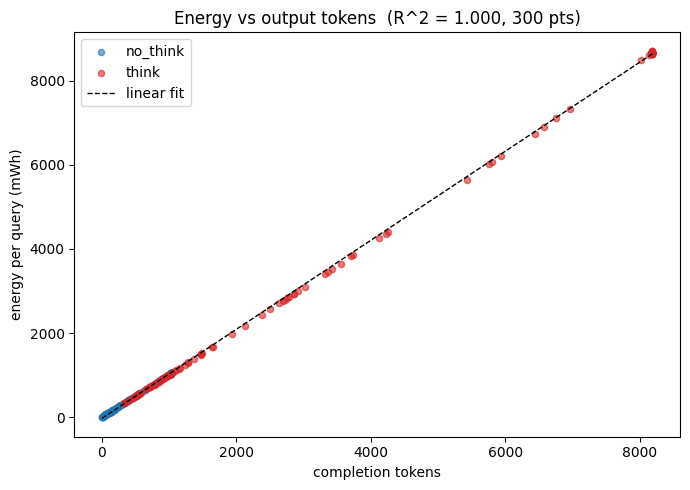

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
for mode, c in [("no_think", "tab:blue"), ("think", "tab:red")]:
    d = df[df["mode"] == mode]
    ax.scatter(d["completion_tokens"], d["energy_wh"] * 1000, s=20, alpha=0.6, label=mode, color=c)

x = df["completion_tokens"].to_numpy(float)
y = (df["energy_wh"] * 1000).to_numpy(float)
mask = np.isfinite(x) & np.isfinite(y)
if mask.sum() > 2:
    slope, intercept = np.polyfit(x[mask], y[mask], 1)
    xs = np.linspace(x[mask].min(), x[mask].max(), 50)
    ax.plot(xs, intercept + slope * xs, "k--", lw=1, label="linear fit")
    resid = y[mask] - (intercept + slope * x[mask])
    ss_tot = np.sum((y[mask] - y[mask].mean()) ** 2)
    r2 = 1 - np.sum(resid ** 2) / ss_tot if ss_tot > 0 else float("nan")
    ax.set_title(f"Energy vs output tokens  (R^2 = {r2:.3f}, {int(mask.sum())} pts)")
ax.set_xlabel("completion tokens"); ax.set_ylabel("energy per query (mWh)"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUTDIR, "scatter_energy_vs_tokens.png"), dpi=120); plt.show()

### 9b. Energy distribution: think vs no-think

/tmp/ipykernel_12241/2687505222.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=["no_think", "think"])


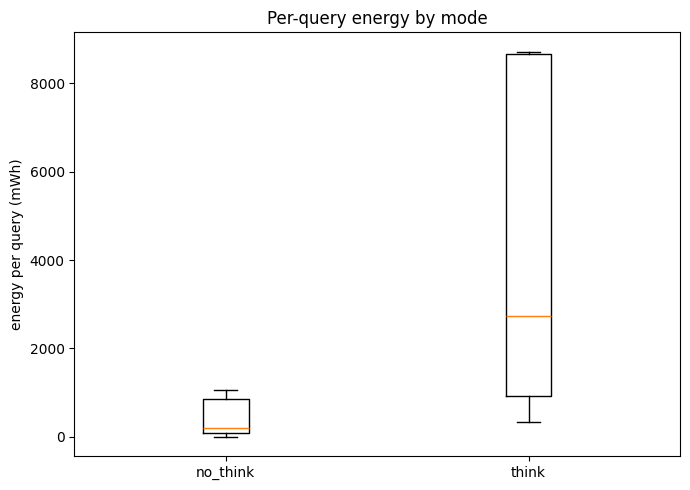

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))
data = [(df[df["mode"] == m]["energy_wh"] * 1000).dropna() for m in ["no_think", "think"]]
ax.boxplot(data, labels=["no_think", "think"])
ax.set_ylabel("energy per query (mWh)"); ax.set_title("Per-query energy by mode")
plt.tight_layout(); plt.savefig(os.path.join(OUTDIR, "energy_box.png"), dpi=120); plt.show()

## 10. Budget extrapolation for Phase 1

Uses the measured mean seconds/query and Wh/query to estimate the cost of the
full paired study (both modes on all OptimalThinkingBench queries). Use this to
right-size the GPU-credit request **before** launching it.

In [22]:
mean_s = df.groupby("mode")["latency_s"].mean().to_dict()
mean_wh = df.groupby("mode")["energy_wh"].mean().to_dict()

N_FULL = 1460 + 610      # OverthinkingBench + UnderthinkingBench (incl. math)
REPS_FULL = 3
per_query_s = sum(mean_s.get(m, 0) for m in ["think", "no_think"])
per_query_wh = sum(mean_wh.get(m, 0) for m in ["think", "no_think"])
gpu_hours = per_query_s * N_FULL * REPS_FULL / 3600
kwh = per_query_wh * N_FULL * REPS_FULL / 1000

print(f"Per query (both modes): {per_query_s:.1f} s, {per_query_wh*1000:.1f} mWh")
print(f"Full paired study ({N_FULL} queries x {REPS_FULL} reps, both modes):")
print(f"  ~{gpu_hours:.1f} GPU-hours   ~{kwh:.2f} kWh on this GPU")

Per query (both modes): 54.6 s, 4522.2 mWh
Full paired study (2070 queries x 3 reps, both modes):
  ~94.2 GPU-hours   ~28.08 kWh on this GPU


## 11. Notes, caveats & next steps

**Sanity checks before trusting numbers**
- Confirm `BACKEND == "vllm"` (else the pilot ran on the HF fallback; Wh won't match Phase 1).
- Confirm `think_tokens` is ~0 for `no_think` rows and hundreds–thousands for `think` rows.
- Confirm Zeus was used (not the power-sampling fallback) — check the cell-6 print.

**Known pilot limitations (handled in later phases)**
- Open-ended-long answers are unscored → add an LLM/reward-model judge (Phase 1).
- Math subsets are excluded from the HF release → add via the OTB `prepare` workflow.
- Per-query energy here is **low-concurrency**; batched-serving attribution is a separate study (CLAUDE.md §4.5).
- Optional cross-check: wrap the loop in CodeCarbon (`pip install codecarbon`) and compare total kWh to `df["energy_wh"].sum()`.

**What to report back from this pilot**
1. The cell-9a `R^2` and the scatter shape (proportional? or do think-heavy points peel off?).
2. The per-mode mean Wh/query and the cell-10 GPU-hour estimate.
3. Whether all three plumbing checks passed (Zeus, vLLM thinking toggle, parsing).